<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/17-deep-learning-pytorch/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: A Clothing Classifier

An online clothes shop gets thousands of product photos a day from its suppliers, and each one has to be filed under the right category. We'll train a neural network to do the filing: it looks at a small photo and says whether it shows a T-shirt, a pair of trousers, a bag, an ankle boot, or one of six other kinds of item.

The data is **Fashion-MNIST**, published by Han Xiao, Kashif Rasul and Roland Vollgraf at Zalando Research in 2017: 70,000 greyscale photos of clothing from Zalando's catalogue, each shrunk to 28 x 28 pixels. It was made as a harder replacement for the handwritten digits of MNIST, and it's still one of the standard first datasets for deep learning.

The plan:

1. Load and look at the data, and set aside a validation set.
2. Build a **baseline** that the network has to beat.
3. Train an **MLP**, and diagnose what goes wrong.
4. Fix it with **dropout, weight decay and a learning-rate schedule**.
5. Test the chosen model **once** on the test set, and study its mistakes.
6. Save the model, load it back, and write a function that classifies new images.

Everything runs on a CPU in a few minutes. On Colab, a GPU makes no real difference for a network this small, so you don't need to change the runtime.

## Setup

The four data files (about 30 MB in total) are downloaded from the Fashion-MNIST repository on GitHub the first time you run this, and saved in `data/fashion_mnist/` so later runs read them from disk.

In [1]:
import gzip
import time
import urllib.request
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SOURCE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FOLDER = Path("data") / "fashion_mnist"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]

FOLDER.mkdir(parents=True, exist_ok=True)
for name in FILES:
    if not (FOLDER / name).exists():
        print("downloading", name)
        urllib.request.urlretrieve(SOURCE + name, FOLDER / name)


def read_idx(path):
    """Read a file in the IDX format used by MNIST and Fashion-MNIST."""
    with gzip.open(path, "rb") as f:
        data = f.read()
    n_dims = data[3]                                            # the 4th byte of the header is the number of dimensions
    shape = [int.from_bytes(data[4 + 4 * i: 8 + 4 * i], "big") for i in range(n_dims)]
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * n_dims).reshape(shape)


train_images, train_labels = read_idx(FOLDER / FILES[0]), read_idx(FOLDER / FILES[1])
test_images, test_labels = read_idx(FOLDER / FILES[2]), read_idx(FOLDER / FILES[3])
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("PyTorch", torch.__version__)
print("training images:", train_images.shape, train_images.dtype, "  test images:", test_images.shape)

PyTorch 2.15.0+cu132
training images: (60000, 28, 28) uint8   test images: (10000, 28, 28)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. A first look

Each image is a 28 x 28 grid of numbers from 0 (black) to 255 (white). Here are the first eight training images of each class:

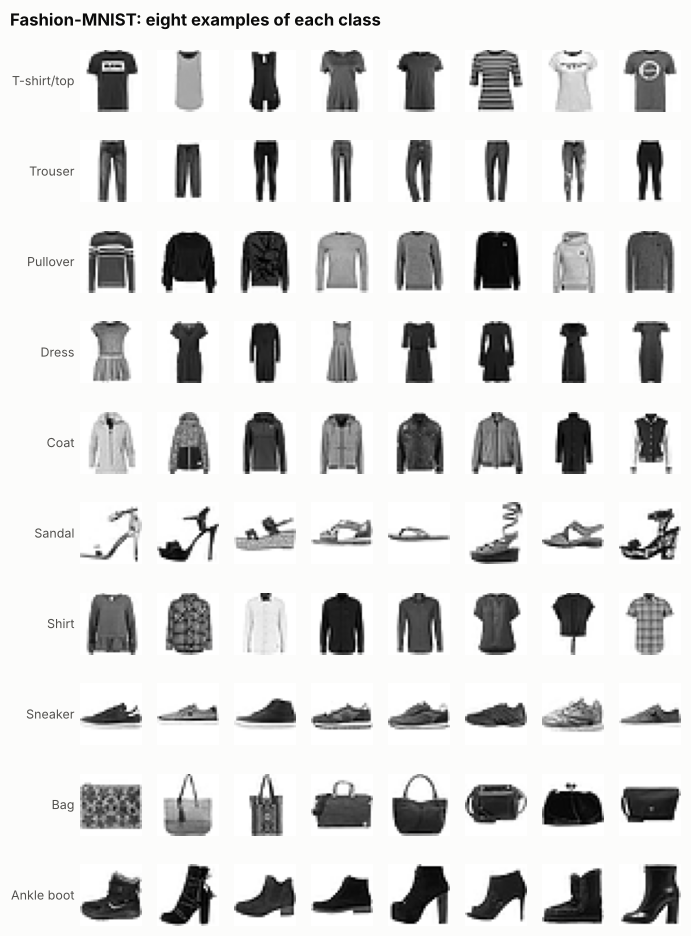

training images per class: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


In [3]:
fig, axes = plt.subplots(10, 8, figsize=(7, 9.6))
for c, name in enumerate(CLASSES):
    examples = np.flatnonzero(train_labels == c)[:8]
    for j, i in enumerate(examples):
        ax = axes[c, j]
        ax.imshow(train_images[i], cmap="gray_r", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[c, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Fashion-MNIST: eight examples of each class", x=0.02, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

counts = np.bincount(train_labels, minlength=10)
print("training images per class:", dict(zip(CLASSES, counts.tolist())))

(The images are drawn with dark ink on a light background, which is easier to look at; the data itself has white clothes on black.)

Some classes look easy: trousers, bags and the three kinds of footwear have distinctive shapes. Others will be hard. T-shirts, pullovers, coats and shirts are all roughly the same shape at this size, and the differences are details like sleeve length, a collar or buttons. Expect most mistakes there.

Every class has exactly 6,000 training images, so plain accuracy is a fair measure here, and guessing gives 10%.

## 2. Validation set and scaling

The 10,000 test images are kept aside until the very end. To choose between models, we split the 60,000 training images into 50,000 for training and 10,000 for **validation**.

Networks train best when the inputs are on a small scale around zero, so we flatten each image into 784 numbers, divide by 255, and standardise with the mean and standard deviation of the **training** pixels (not the validation or test pixels, which would leak information, as in Module 12):

In [4]:
rng = np.random.default_rng(0)
order = rng.permutation(len(train_images))
train_idx, valid_idx = order[:50_000], order[50_000:]


def to_tensor(images):
    return torch.tensor(images.reshape(len(images), -1), dtype=torch.float32) / 255


X_train, X_valid, X_test = to_tensor(train_images[train_idx]), to_tensor(train_images[valid_idx]), to_tensor(test_images)
y_train, y_valid, y_test = (torch.tensor(a, dtype=torch.long) for a in (train_labels[train_idx], train_labels[valid_idx], test_labels))

MEAN, STD = X_train.mean().item(), X_train.std().item()
X_train, X_valid, X_test = ((X - MEAN) / STD for X in (X_train, X_valid, X_test))
print(f"pixel mean {MEAN:.4f}, standard deviation {STD:.4f}")
print("train", tuple(X_train.shape), " valid", tuple(X_valid.shape), " test", tuple(X_test.shape))

valid_loader = DataLoader(TensorDataset(X_valid, y_valid), batch_size=1000)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=1000)


def make_train_loader(seed=0):
    g = torch.Generator().manual_seed(seed)           # a fixed shuffling order, so results repeat
    return DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True, generator=g)

pixel mean 0.2864, standard deviation 0.3532
train (50000, 784)  valid (10000, 784)  test (10000, 784)


## 3. The training tools

These are the functions from the lesson, plus `fit`, which trains for a number of epochs, records the curves, and keeps a copy of the weights from the epoch with the **best validation loss** (early stopping, Section 11 of the lesson).

In [5]:
def train_epoch(model, loader, loss_fn, optimizer, scheduler=None):
    model.train()
    total, count = 0.0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        if scheduler is not None:                     # OneCycleLR changes the rate after every batch
            scheduler.step()
        total += loss.item() * len(xb)
        count += len(xb)
    return total / count


@torch.no_grad()
def evaluate(model, loader, loss_fn=nn.CrossEntropyLoss()):
    model.eval()
    total, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        count += len(xb)
    return total / count, correct / count


def fit(model, epochs, optimizer, scheduler=None, every=5):
    loss_fn = nn.CrossEntropyLoss()
    loader = make_train_loader()
    curves = {"train loss": [], "valid loss": [], "valid accuracy": []}
    best_loss, best_state, start = float("inf"), None, time.time()
    for epoch in range(epochs):
        curves["train loss"].append(train_epoch(model, loader, loss_fn, optimizer, scheduler))
        valid_loss, valid_acc = evaluate(model, valid_loader, loss_fn)
        curves["valid loss"].append(valid_loss)
        curves["valid accuracy"].append(valid_acc)
        if valid_loss < best_loss:
            best_loss = valid_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if (epoch + 1) % every == 0:
            print(f"epoch {epoch + 1:>2}: train loss {curves['train loss'][-1]:.3f}   "
                  f"valid loss {valid_loss:.3f}   valid accuracy {valid_acc:.3f}")
    curves["best epoch"] = int(np.argmin(curves["valid loss"])) + 1
    curves["best state"] = best_state
    curves["seconds"] = time.time() - start
    return curves


STYLES = {"linear": (PALETTE[0], "-"), "MLP": (PALETTE[1], "--"),
          "MLP + dropout, weight decay, one-cycle": (PALETTE[2], "-.")}   # each model keeps its colour in every plot


def plot_curves(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for label, c in results.items():
        color, dash = STYLES[label]
        epochs = range(1, len(c["train loss"]) + 1)
        axes[0].plot(epochs, c["train loss"], color=color, linestyle=dash, alpha=0.45)
        axes[0].plot(epochs, c["valid loss"], color=color, linestyle=dash, label=label)
        axes[1].plot(epochs, c["valid accuracy"], color=color, linestyle=dash, label=label)
    axes[0].set_title("Loss (pale: training, strong: validation)")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=13)
    plt.tight_layout()
    plt.show()

## 4. A baseline: one linear layer

Before any hidden layers, the simplest model: a single `nn.Linear(784, 10)`. With cross-entropy loss, this is **multinomial logistic regression**, the linear classifier from Module 12, trained by PyTorch instead of scikit-learn. Each class gets one weight per pixel, so the model can only learn "which pixels tend to be bright for this class". Whatever the network achieves later has to beat this.

In [6]:
torch.manual_seed(0)
linear = nn.Linear(784, 10)
results = {"linear": fit(linear, epochs=10, optimizer=torch.optim.Adam(linear.parameters(), lr=1e-3))}
print(f"best validation accuracy {max(results['linear']['valid accuracy']):.3f}   ({results['linear']['seconds']:.0f} seconds)")

epoch  5: train loss 0.410   valid loss 0.435   valid accuracy 0.852


epoch 10: train loss 0.392   valid loss 0.454   valid accuracy 0.846
best validation accuracy 0.852   (6 seconds)


Already far better than the 10% from guessing. Because the model is linear, its weights can be drawn as images, one per class: blue pixels push towards the class, red pixels push away from it.

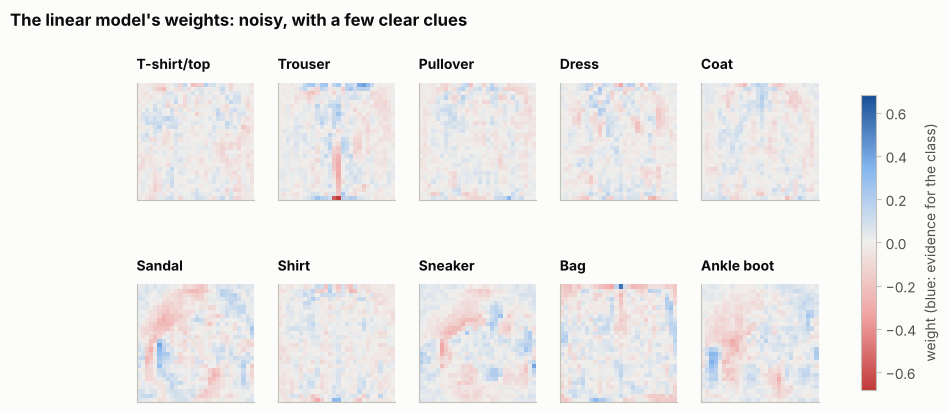

In [7]:
weights = linear.weight.detach().numpy().reshape(10, 28, 28)
limit = np.abs(weights).max()
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for ax, w, name in zip(axes.flat, weights, CLASSES):
    image = ax.imshow(w, cmap=DIVERGING.reversed(), vmin=-limit, vmax=limit)
    ax.set_title(name, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.colorbar(image, ax=axes, shrink=0.8, label="weight (blue: evidence for the class)")
fig.suptitle("The linear model's weights: noisy, with a few clear clues", x=0.01, ha="left", fontweight="bold")
plt.show()

The weights are noisy, but a few clues stand out. The trouser weights are strongly negative (red) in a thin strip at the bottom centre: that's the gap between the legs, and a bright pixel there is strong evidence **against** trousers. The bag has positive weights at the top centre, where handles and straps are. The three footwear classes have curved bands that follow the outline of a shoe.

A linear model scores an image by adding up evidence pixel by pixel, with one fixed pattern per class. It can't express ideas like "a collar, wherever it is" or "long sleeves **and** buttons". Combining simple clues into more complex ones like that is what hidden layers are for.

## 5. An MLP

Now a network with two hidden layers, 784 -> 256 -> 128 -> 10, with ReLU activations, trained with Adam for 30 epochs:

In [8]:
def mlp(hidden=(256, 128), dropout=0.0):
    layers, n_in = [], 784
    for n_out in hidden:
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        n_in = n_out
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers)


torch.manual_seed(0)
plain = mlp()
print(f"parameters: {sum(p.numel() for p in plain.parameters()):,}")
results["MLP"] = fit(plain, epochs=30, optimizer=torch.optim.Adam(plain.parameters(), lr=1e-3))
print(f"best epoch {results['MLP']['best epoch']}, best validation accuracy {max(results['MLP']['valid accuracy']):.3f}   ({results['MLP']['seconds']:.0f} seconds)")

parameters: 235,146


epoch  5: train loss 0.268   valid loss 0.316   valid accuracy 0.888


epoch 10: train loss 0.200   valid loss 0.335   valid accuracy 0.891


epoch 15: train loss 0.156   valid loss 0.358   valid accuracy 0.890


epoch 20: train loss 0.126   valid loss 0.377   valid accuracy 0.896


epoch 25: train loss 0.096   valid loss 0.454   valid accuracy 0.889


epoch 30: train loss 0.078   valid loss 0.527   valid accuracy 0.890
best epoch 5, best validation accuracy 0.896   (33 seconds)


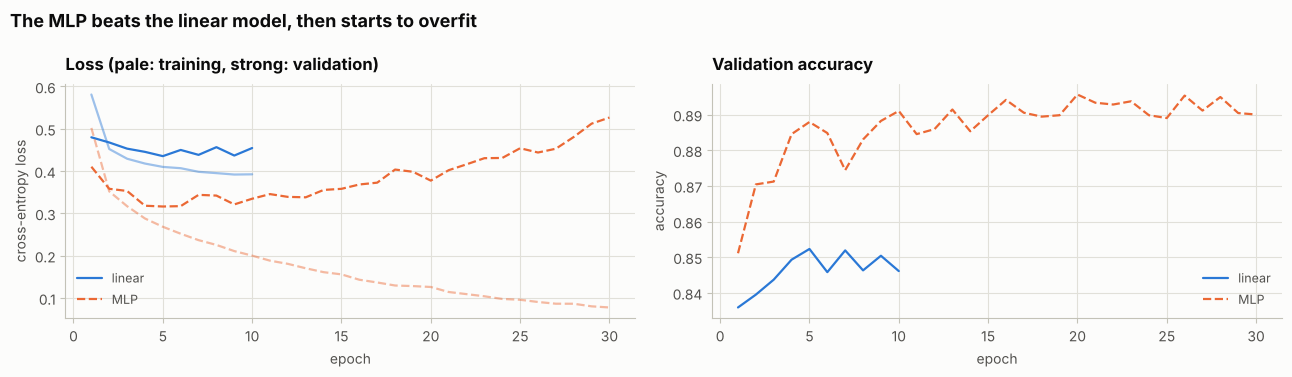

In [9]:
plot_curves(results, "The MLP beats the linear model, then starts to overfit")

The hidden layers help: validation accuracy jumps by several points over the linear model. But look at the loss curves. The training loss keeps falling all the way to the end, while the **validation loss reaches its lowest point within the first few epochs and then rises**. That's overfitting (Module 12, and Section 11 of the lesson): the network has about 235,000 weights for 50,000 images, and after a while it starts memorising details of the training images that don't carry over to new ones.

Validation accuracy suffers much less than validation loss. The loss also measures **confidence**, and an overfitting network becomes overconfident: it keeps most of its right answers but grows very sure of its wrong ones, which cross-entropy punishes heavily. So a rising validation loss is an early warning, and the right signal for early stopping.

## 6. Fixing the overfitting

Three tools from the lesson, used together:

- **Dropout** of 0.3 after each hidden layer, and wider layers (512 and 256), since dropout reduces the network's effective capacity.
- **Weight decay** with **AdamW**, which applies the decay directly to the weights (Exercise 11).
- A **one-cycle learning-rate schedule**: the rate rises to a high value over the first 30% of training, then decays to a very low one. The high rate explores quickly, and the low rate at the end lets the network settle into a good minimum instead of bouncing around it.

In [10]:
torch.manual_seed(0)
regularised = mlp(hidden=(512, 256), dropout=0.3)
epochs = 30
optimizer = torch.optim.AdamW(regularised.parameters(), lr=1e-3, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=epochs, steps_per_epoch=len(make_train_loader()))
print(f"parameters: {sum(p.numel() for p in regularised.parameters()):,}")
results["MLP + dropout, weight decay, one-cycle"] = fit(regularised, epochs, optimizer, scheduler)
best = results["MLP + dropout, weight decay, one-cycle"]
print(f"best epoch {best['best epoch']}, best validation accuracy {max(best['valid accuracy']):.3f}   ({best['seconds']:.0f} seconds)")

parameters: 535,818


epoch  5: train loss 0.386   valid loss 0.367   valid accuracy 0.866


epoch 10: train loss 0.385   valid loss 0.362   valid accuracy 0.866


epoch 15: train loss 0.331   valid loss 0.345   valid accuracy 0.877


epoch 20: train loss 0.267   valid loss 0.309   valid accuracy 0.889


epoch 25: train loss 0.202   valid loss 0.294   valid accuracy 0.897


epoch 30: train loss 0.173   valid loss 0.294   valid accuracy 0.900
best epoch 28, best validation accuracy 0.900   (75 seconds)


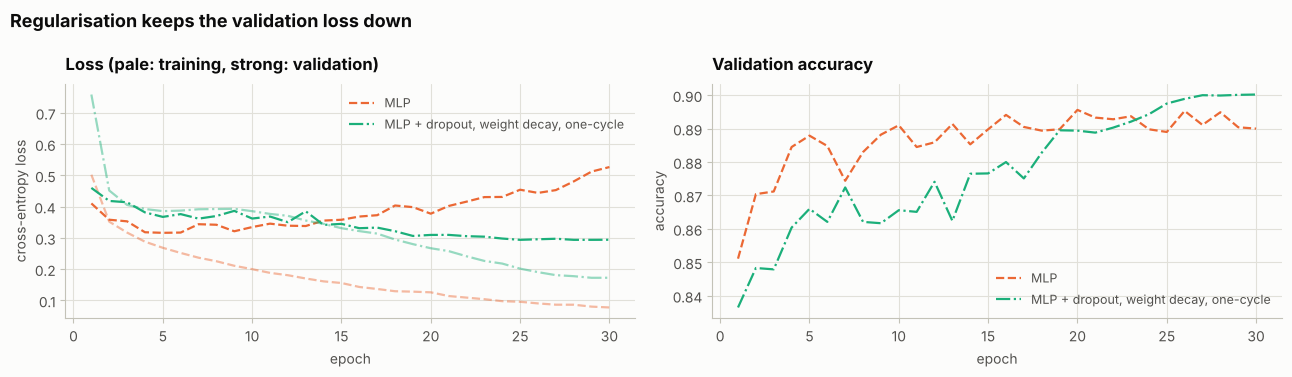

In [11]:
plot_curves({k: results[k] for k in ["MLP", "MLP + dropout, weight decay, one-cycle"]}, "Regularisation keeps the validation loss down")

With regularisation, the gap between training and validation loss stays much smaller, and the validation loss no longer climbs. The network has more than twice as many weights as the plain MLP, yet it overfits less: how training is controlled matters as much as the size of the network.

Two more things to notice in the curves:

- **For the first half, the training loss is above the validation loss.** That looks wrong, but it's dropout: during training, 30% of the hidden units are switched off at random, so the network is handicapped; during evaluation it gets to use all of them.
- **The schedule shapes the progress.** While the rate is high, the validation loss barely improves. Most of the gain comes in the second half, as the rate falls and the network settles.

Here are the three models side by side, each at its best validation epoch:

In [12]:
print(f"{'model':<40}{'best epoch':>11}{'valid loss':>12}{'valid accuracy':>16}")
for label, c in results.items():
    i = c["best epoch"] - 1
    print(f"{label:<40}{c['best epoch']:>11}{c['valid loss'][i]:>12.3f}{c['valid accuracy'][i]:>16.3f}")

model                                    best epoch  valid loss  valid accuracy
linear                                            5       0.435           0.852
MLP                                               5       0.316           0.888
MLP + dropout, weight decay, one-cycle           28       0.294           0.900


The regularised network wins on validation loss and accuracy, so it's the one we choose. We restore its weights from the best epoch, and only now, with the choice made, look at the test set.

## 7. The test set

The test set has been untouched until now, so this is an honest estimate of how the model will do on new photos. For comparison we evaluate all three models, but the decision was already made on the validation set; picking the winner by test score would make the test score optimistic again.

In [13]:
linear.load_state_dict(results["linear"]["best state"])
plain.load_state_dict(results["MLP"]["best state"])
regularised.load_state_dict(best["best state"])

for label, model in [("linear", linear), ("MLP", plain), ("MLP + dropout, weight decay, one-cycle", regularised)]:
    test_loss, test_acc = evaluate(model, test_loader)
    print(f"{label:<40} test accuracy {test_acc:.3f}")

linear                                   test accuracy 0.841
MLP                                      test accuracy 0.881


MLP + dropout, weight decay, one-cycle   test accuracy 0.897


The test accuracies are close to the validation accuracies, which is what you'd hope: the validation set gave a fair picture. The final model gets roughly 9 photos in 10 right. Which ones does it get wrong?

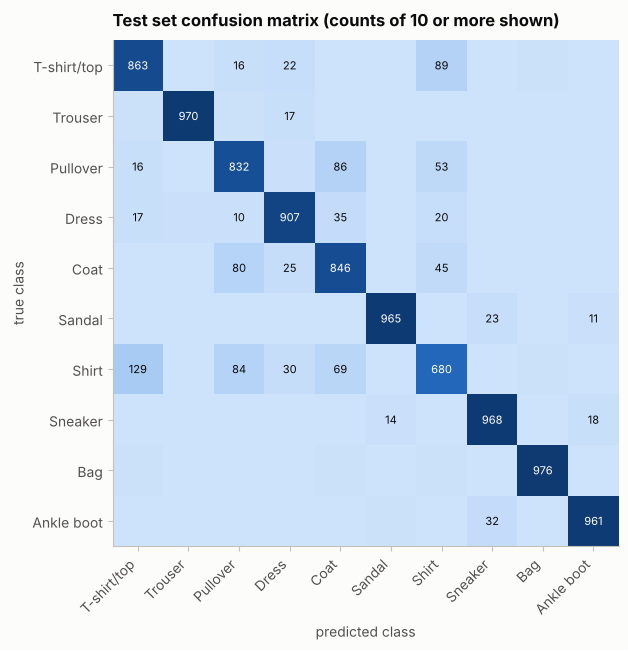

Shirt        0.680
Pullover     0.832
Coat         0.846
T-shirt/top  0.863
Dress        0.907
Ankle boot   0.961
Sandal       0.965
Sneaker      0.968
Trouser      0.970
Bag          0.976


In [14]:
@torch.no_grad()
def predict_proba(model, X):
    model.eval()
    return torch.softmax(model(X), dim=1)


probabilities = predict_proba(regularised, X_test)
predicted = probabilities.argmax(dim=1).numpy()
truth = y_test.numpy()

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (truth, predicted), 1)
rates = confusion / confusion.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8, 6.6))
ax.imshow(rates, cmap="course_blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if confusion[i, j] >= 10:
            ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=8,
                    color="white" if rates[i, j] > 0.5 else INK)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.grid(False)
ax.set_title("Test set confusion matrix (counts of 10 or more shown)")
plt.tight_layout()
plt.show()

per_class = np.diag(rates)
for c in np.argsort(per_class):
    print(f"{CLASSES[c]:<12} {per_class[c]:.3f}")

The errors are concentrated exactly where the first look suggested. **Shirts** are by far the hardest class, and they're mostly confused with T-shirts, pullovers and coats. The four upper-body classes are mixed up with each other; trousers, bags and footwear are almost always right, and the footwear mistakes stay within footwear (a sneaker taken for a sandal or an ankle boot).

Here are some of the test images the model gets wrong, with its confidence in its answer:

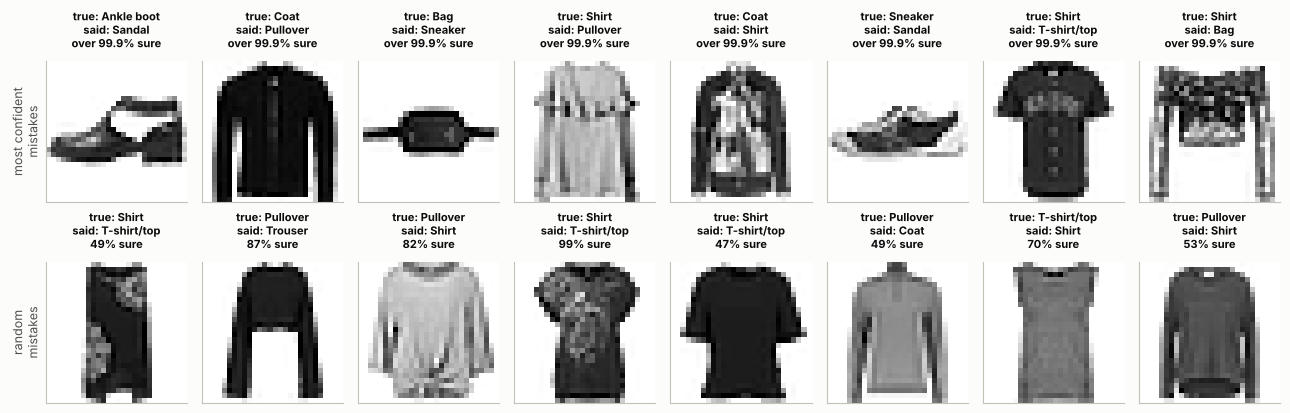

In [15]:
def sure_text(p):
    return "over 99.9% sure" if p > 0.999 else f"{p:.0%} sure"     # avoid rounding 0.9996 up to "100%"


wrong = np.flatnonzero(predicted != truth)
confidence = probabilities.max(dim=1).values.numpy()
show = wrong[np.argsort(-confidence[wrong])][:8].tolist() + rng.choice(wrong, 8, replace=False).tolist()

fig, axes = plt.subplots(2, 8, figsize=(13, 4.4))
for ax, i in zip(axes.flat, show):
    ax.imshow(test_images[i], cmap="gray_r", vmin=0, vmax=255)
    ax.set_title(f"true: {CLASSES[truth[i]]}\nsaid: {CLASSES[predicted[i]]}\n{sure_text(confidence[i])}", fontsize=8, loc="center")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].set_ylabel("most confident\nmistakes", fontsize=9)
axes[1, 0].set_ylabel("random\nmistakes", fontsize=9)
plt.tight_layout()
plt.show()

Many of these are hard even for a person at this resolution, and some of the labels look debatable: at 28 x 28 pixels a shirt and a T-shirt can be nearly identical, and the line between a pullover and a coat is often a matter of opinion. Every real dataset has some ambiguous or wrong labels (that's what the noisy-label experiment in the lesson simulated), and no model can get them all right. Looking at the most confident mistakes is a good habit: it's the fastest way to find labelling problems and to understand what the model is actually responding to.

Since the model outputs probabilities, it's worth asking whether they mean what they say (calibration, Module 13). We group the test images by the model's confidence and compare it with the actual accuracy in each group:

In [16]:
bins = [0, 0.5, 0.7, 0.9, 0.99, 1.0]
group = np.digitize(confidence, bins[1:-1])
print(f"{'confidence':<14}{'images':>8}{'mean confidence':>18}{'accuracy':>11}")
for b in range(len(bins) - 1):
    mask = group == b
    print(f"{bins[b]:.2f} to {bins[b + 1]:.2f}  {mask.sum():>8}{confidence[mask].mean():>18.3f}{(predicted[mask] == truth[mask]).mean():>11.3f}")

confidence      images   mean confidence   accuracy
0.00 to 0.50       283             0.427      0.417
0.50 to 0.70       920             0.597      0.561
0.70 to 0.90      1210             0.808      0.770
0.90 to 0.99      1503             0.958      0.906
0.99 to 1.00      6084             0.999      0.993


The network is at least 99% sure about most of the test images, and nearly always right when it is. Lower down, the probabilities still order the images well (higher confidence, higher accuracy), but in every group the accuracy is a few points **below** the mean confidence: the network is somewhat overconfident, as networks trained with cross-entropy often are. Module 13's calibration methods (or "temperature scaling", which divides the logits by a single number fitted on the validation set) would correct that.

For the shop, this suggests a practical design: file the photos the model is very sure about automatically, and send the uncertain ones to a person. Module 13's threshold tools apply directly.

## 8. Saving the model and using it

To use the model elsewhere we need three things: the architecture (the `mlp` function and its settings), the trained weights, and the **preprocessing**, here the mean and standard deviation used for scaling. Forgetting the preprocessing is one of the most common deployment bugs: the model then receives inputs on a different scale from the ones it was trained on, and its predictions quietly become nonsense.

In [17]:
Path("work").mkdir(exist_ok=True)
torch.save({"state_dict": regularised.state_dict(), "hidden": (512, 256), "dropout": 0.3,
            "mean": MEAN, "std": STD, "classes": CLASSES}, "work/fashion_mlp.pt")
print(f"saved: {Path('work/fashion_mlp.pt').stat().st_size / 1e6:.1f} MB")

saved = torch.load("work/fashion_mlp.pt", weights_only=True)
loaded = mlp(hidden=saved["hidden"], dropout=saved["dropout"])
loaded.load_state_dict(saved["state_dict"])


def classify(images, model=loaded, info=saved):
    """Classify raw 28 x 28 images (values 0 to 255). Returns (class names, confidences)."""
    images = np.asarray(images, dtype=np.float32).reshape(-1, 784) / 255
    X = (torch.tensor(images) - info["mean"]) / info["std"]
    probabilities = predict_proba(model, X)
    confidence, index = probabilities.max(dim=1)
    return [info["classes"][i] for i in index.tolist()], confidence.tolist()


names, sure = classify(test_images[:5])
for name, p, t in zip(names, sure, test_labels[:5]):
    print(f"predicted {name:<12} {sure_text(p):<16} true: {CLASSES[t]}")
print("\nthe loaded model's test accuracy:", round(evaluate(loaded, test_loader)[1], 3))

saved: 2.1 MB
predicted Ankle boot   over 99.9% sure  true: Ankle boot
predicted Pullover     100% sure        true: Pullover
predicted Trouser      over 99.9% sure  true: Trouser
predicted Trouser      over 99.9% sure  true: Trouser
predicted Shirt        96% sure         true: Shirt



the loaded model's test accuracy: 0.897


`classify` takes raw pixel values, exactly as a new photo would arrive, and does the scaling itself, so nobody using it needs to remember the preprocessing. The loaded model gives the same test accuracy as before, so the save and load worked.

`weights_only=True` makes `torch.load` refuse to run arbitrary code hidden in the file, which matters when loading files from other people. Saving the settings and the scaling numbers in the same file as the weights keeps everything needed to rebuild the model in one place.

## What we learned

- **Start with a baseline.** A single linear layer already gets about 84% of the test images right, and drawing its weights shows what it learns: one fixed pattern of evidence per class.
- **Hidden layers help**, but an MLP with enough weights starts to overfit within a few epochs. The validation loss shows it before the accuracy does.
- **Dropout, weight decay and a one-cycle schedule** together keep the validation loss down, even in a network twice the size.
- **Choose on validation, report on test.** The test set was used once, after the choice was made.
- **Study the mistakes.** They cluster in the upper-body classes, especially shirts, and some of them are arguably labelling problems.
- **Save the preprocessing with the model**, and wrap the whole thing in a function that takes raw inputs.

**Try next:**

- Change the hidden sizes, the dropout rate or the weight decay, and see how the validation curves move. Keep the test set out of it.
- Train for more epochs with the one-cycle schedule. Does it keep improving?
- Remove the scaling step (use raw values from 0 to 255) and train the plain MLP again. What happens to the loss in the first epoch?

An MLP treats each image as a list of 784 unrelated numbers: shuffle the pixels the same way in every image, and it would learn just as well. It has no idea that neighbouring pixels belong together, or that a collar is still a collar when it moves two pixels to the left. **Convolutional networks** build that knowledge in, and in Module 18 you'll see how much difference that makes on images like these.